In [1]:
# load data
import pandas as pd

df = pd.read_csv('Student_Depression_Dataset.csv')
df

,Gender,Age,Family_background,Relationship_status,Marital_status,Living_style,Current_semester,CGPA,friend_circle,Health_condition,Cost_without_study,Home_division,Depression
0,Female,22,Middle class,Single,Unmarried,Bachelor,8,3.43,Yes,Critical,10113,Chittagong,Yes
1,Male,19,Middle class,Single,Unmarried,Bachelor,2,3.70,Yes,Abnormal,13815,Chittagong,Yes
2,Male,23,Middle class,Single,Unmarried,Family,8,3.28,No,Abnormal,15450,Dhaka,Yes
3,Male,20,Middle class,Complicated,Unmarried,Family,2,3.77,No,Good,17413,Dhaka,No
4,Female,21,Middle class,Single,Unmarried,Family,1,4.00,No,Abnormal,16693,Dhaka,Yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...
4459,Female,26,Middle class,In a Relationship,Separated,Family,11,2.97,No,Critical,12619,Khulna,Yes
4460,Male,28,Lower Middle class,Single,Unmarried,Family,8,2.60,No,Normal,2806,Rajshahi,Yes
4461,Female,23,Middle class,In a Relationship,Married,Bachelor,10,2.80,No,Good,14066,Rajshahi,No
4462,Female,23,Middle class,Complicated,Married,Family,5,3.00,Yes,Normal,14338,Barisal,No


In [2]:
# EDA
print(f'Cek 5 data teratas \n {df.head()} \n')

print(f'Cek tipe data \n {df.dtypes} \n')

print(f'Cek missing values \n {df.isnull().sum()}')

Cek 5 data teratas 
    Gender  Age Family_background Relationship_status Marital_status  \
0  Female   22      Middle class              Single      Unmarried   
1    Male   19      Middle class              Single      Unmarried   
2    Male   23      Middle class              Single      Unmarried   
3    Male   20      Middle class         Complicated      Unmarried   
4  Female   21      Middle class              Single      Unmarried   

  Living_style  Current_semester  CGPA friend_circle Health_condition  \
0     Bachelor                 8  3.43           Yes         Critical   
1     Bachelor                 2  3.70           Yes         Abnormal   
2       Family                 8  3.28            No         Abnormal   
3       Family                 2  3.77            No             Good   
4       Family                 1  4.00            No         Abnormal   

   Cost_without_study Home_division Depression  
0               10113    Chittagong        Yes  
1              

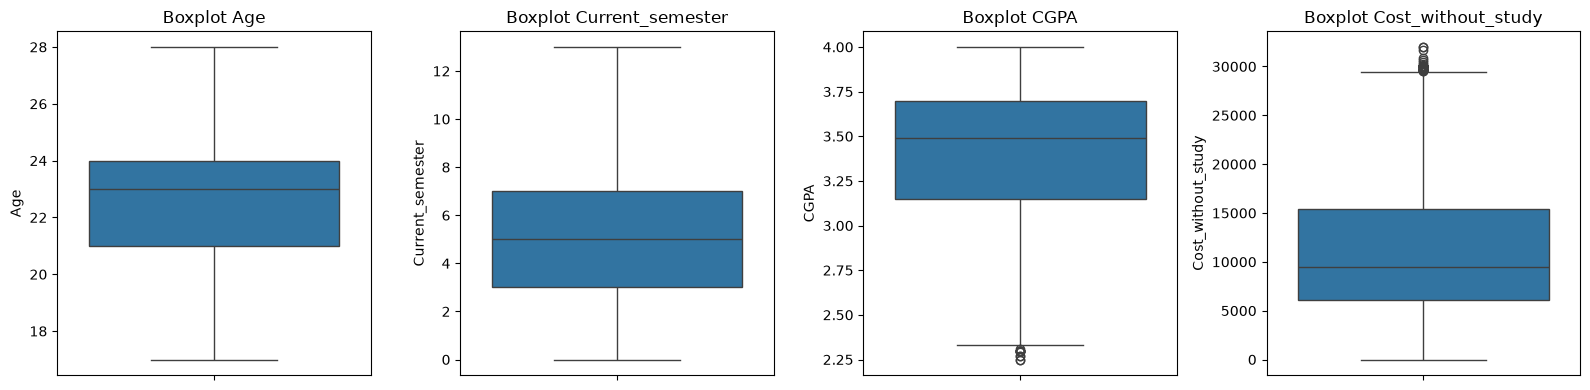

In [3]:
# outlier
import math
import matplotlib.pyplot as plt
import seaborn as sns

numerical_columns = df.select_dtypes(include='number').columns

## Outlier
n_cols = 4  # jumlah plot per baris, silakan diubah
n_rows = math.ceil(len(numerical_columns) / n_cols)

plt.figure(figsize=(4 * n_cols, 4 * n_rows))

for i, column in enumerate(numerical_columns):
    plt.subplot(n_rows, n_cols, i + 1)
    sns.boxplot(y=df[column])
    plt.title(f'Boxplot {column}')

plt.tight_layout()
plt.show()

In [4]:
# handle outlier
numerical_columns = df.select_dtypes(include='number').columns

Q1 = df[numerical_columns].quantile(0.25)
Q3 = df[numerical_columns].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outlier_mask = (
    (df[numerical_columns] < lower_bound) |
    (df[numerical_columns] > upper_bound)
)

outlier_summary = pd.DataFrame({
    'Outlier Count': outlier_mask.sum(),
    'Percentage': outlier_mask.mean() * 100
})

outlier_summary.sort_values(
    by='Outlier Count',
    ascending=False
)

,Outlier Count,Percentage
Cost_without_study,36,0.806452
CGPA,12,0.268817
Current_semester,0,0.000000
Age,0,0.000000


In [7]:
# capping outlier

Q1 = df[numerical_columns].quantile(0.25)
Q3 = df[numerical_columns].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

df[numerical_columns] = df[numerical_columns].clip(
    lower=lower_bound,
    upper=upper_bound,
    axis=1
)

In [8]:
# CEK OUTLIER SETELAH CAPPING

outlier_count = (
    (df[numerical_columns] < lower_bound) |
    (df[numerical_columns] > upper_bound)
).sum()

print(outlier_count)

Age                   0
Current_semester      0
CGPA                  0
Cost_without_study    0
dtype: int64


In [11]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4464 entries, 0 to 4463
Data columns (total 13 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Gender               4464 non-null   str    
 1   Age                  4464 non-null   int64  
 2   Family_background    4464 non-null   str    
 3   Relationship_status  4464 non-null   str    
 4   Marital_status       4464 non-null   str    
 5   Living_style         4464 non-null   str    
 6   Current_semester     4464 non-null   int64  
 7   CGPA                 4464 non-null   float64
 8   friend_circle        4464 non-null   str    
 9   Health_condition     4464 non-null   str    
 10  Cost_without_study   4464 non-null   float64
 11  Home_division        4464 non-null   str    
 12  Depression           4464 non-null   str    
dtypes: float64(2), int64(2), str(9)
memory usage: 453.5 KB


In [14]:
# pemilihan variabel input dan target

X = df.drop(columns=['Depression'])
y = df['Depression']

print("Features (X):", X.shape)
print("Target (y):", y.shape)

print("\nFeature Columns:")
print(X.columns.tolist())

print("\nTarget Distribution:")
print(y.value_counts())

Features (X): (4464, 12)
Target (y): (4464,)

Feature Columns:
['Gender', 'Age', 'Family_background', 'Relationship_status', 'Marital_status', 'Living_style', 'Current_semester', 'CGPA', 'friend_circle', 'Health_condition', 'Cost_without_study', 'Home_division']

Target Distribution:
Depression
No     3263
Yes    1201
Name: count, dtype: int64


In [16]:
# split data

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# CEK HASIL SPLIT
print("X Train:", X_train.shape)
print("X Test:", X_test.shape)
print("Y Train:", y_train.shape)
print("Y Test:", y_test.shape)

X Train: (3571, 12)
X Test: (893, 12)
Y Train: (3571,)
Y Test: (893,)


In [20]:
# training model
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

# Pisahkan kolom numerik dan kategorikal
numeric_cols = X_train.select_dtypes(include=['number']).columns
categorical_cols = X_train.select_dtypes(exclude=['number']).columns

# Preprocessing numerik
numeric_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Preprocessing kategorikal
categorical_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

# Gabungkan preprocessing
preprocessor = ColumnTransformer([
    ('num', numeric_transformer, numeric_cols),
    ('cat', categorical_transformer, categorical_cols)
])

# Buat Logistic Regression
model = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(max_iter=1000))
])

# Training
model.fit(X_train, y_train)

print("Logistic Regression Training Berhasil!")

Logistic Regression Training Berhasil!


In [21]:
# evaluasi model
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

y_pred = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nClassification Report:")
print(classification_report(y_test, y_pred))
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Accuracy: 0.9708846584546472

Classification Report:
              precision    recall  f1-score   support

          No       0.97      0.99      0.98       653
         Yes       0.96      0.93      0.94       240

    accuracy                           0.97       893
   macro avg       0.97      0.96      0.96       893
weighted avg       0.97      0.97      0.97       893


Confusion Matrix:
[[644   9]
 [ 17 223]]


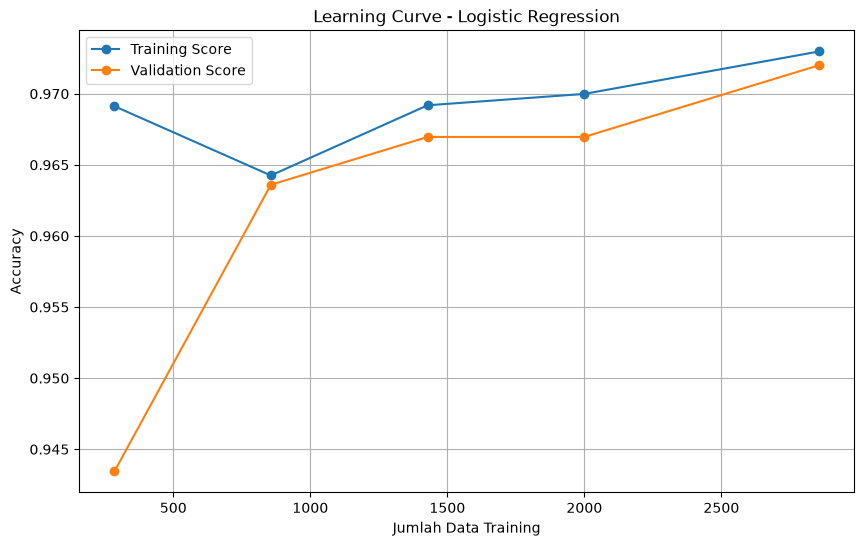

In [22]:
# learning curve
import matplotlib.pyplot as plt

from sklearn.model_selection import learning_curve

train_sizes, train_scores, validation_scores = learning_curve(
    model,
    X_train,
    y_train,
    cv=5,
    scoring='accuracy',
    train_sizes=[0.1, 0.3, 0.5, 0.7, 1.0],
    n_jobs=-1
)

# Hitung rata-rata score
train_mean = train_scores.mean(axis=1)
validation_mean = validation_scores.mean(axis=1)

# Visualisasi
plt.figure(figsize=(10, 6))

plt.plot(train_sizes, train_mean, marker='o', label='Training Score')
plt.plot(train_sizes, validation_mean, marker='o', label='Validation Score')

plt.title('Learning Curve - Logistic Regression')
plt.xlabel('Jumlah Data Training')
plt.ylabel('Accuracy')
plt.legend()
plt.grid()

plt.show()